### Logistic Regression 

1. Data Exploration:

a. Load the dataset and perform exploratory data analysis (EDA).

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score,f1_score ,confusion_matrix, ConfusionMatrixDisplay

In [3]:
df = pd.read_csv("diabetes.csv")

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


*There are all int & float columns*

In [5]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [6]:
df.tail()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1
767,1,93,70,31,0,30.4,0.315,23,0


In [7]:
df.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

*There are no null values*

In [8]:
df.shape

(768, 9)

*There are 768 rows and 9 columns*

In [9]:
df.duplicated().sum()

np.int64(0)

*There are no duplicates*

#### EDA before data cleaning

##### HISTOGRAM

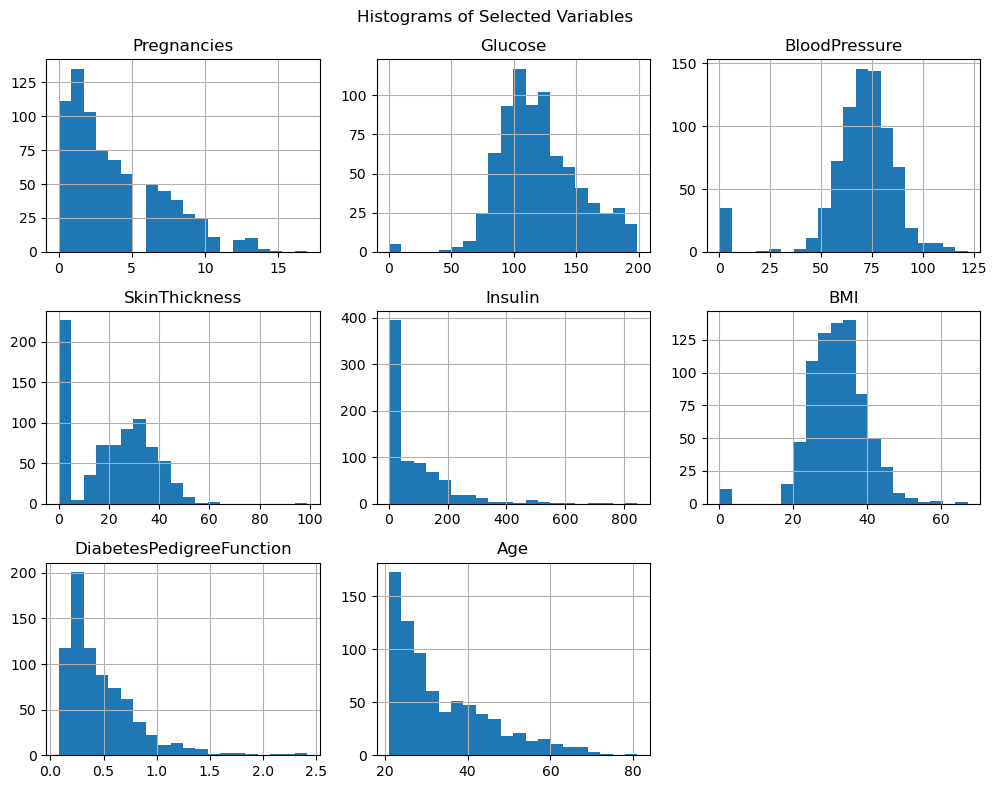

In [10]:
columns = ['Pregnancies',
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI',
    'DiabetesPedigreeFunction',
    'Age']
df[columns].hist(figsize=(10, 8), bins=20)

plt.suptitle("Histograms of Selected Variables")
plt.tight_layout()
plt.show()

##### BAR GRAPH

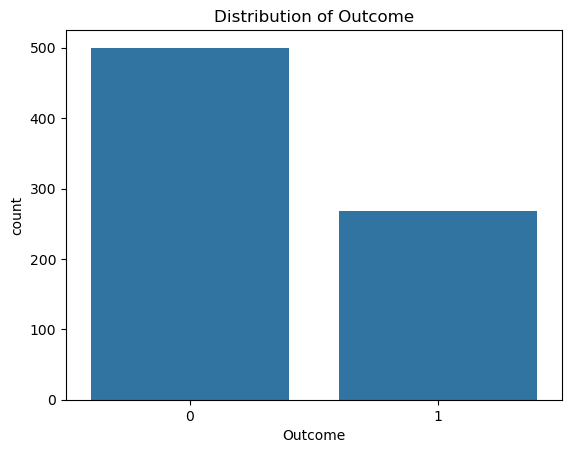

In [11]:
sns.countplot(x='Outcome', data=df)
plt.title("Distribution of Outcome")
plt.show()

##### BOX PLOT

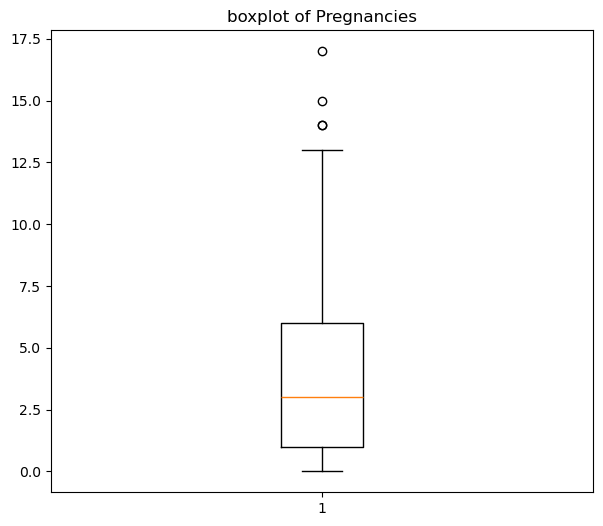

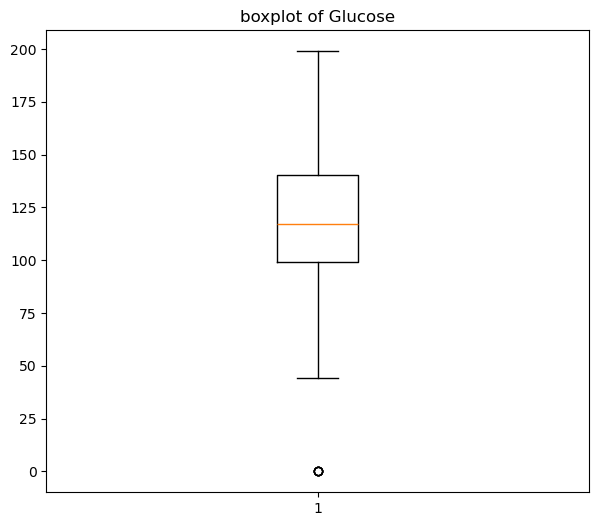

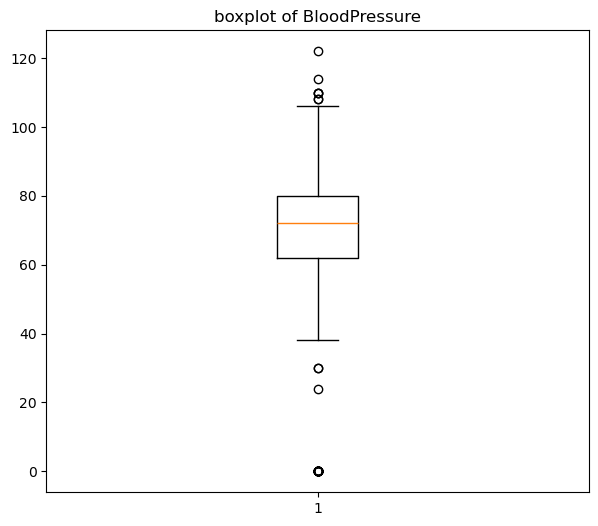

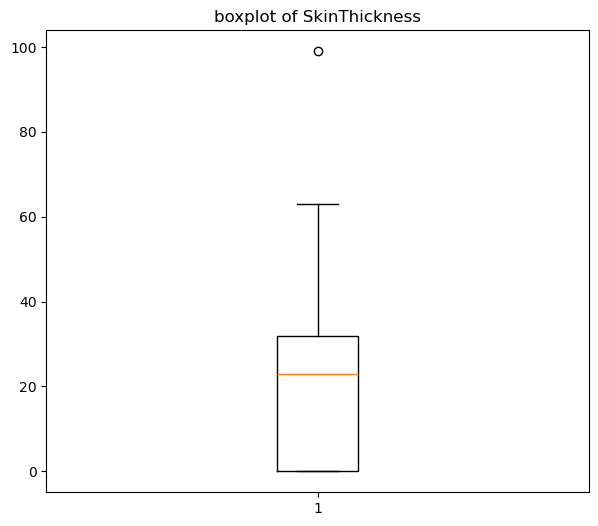

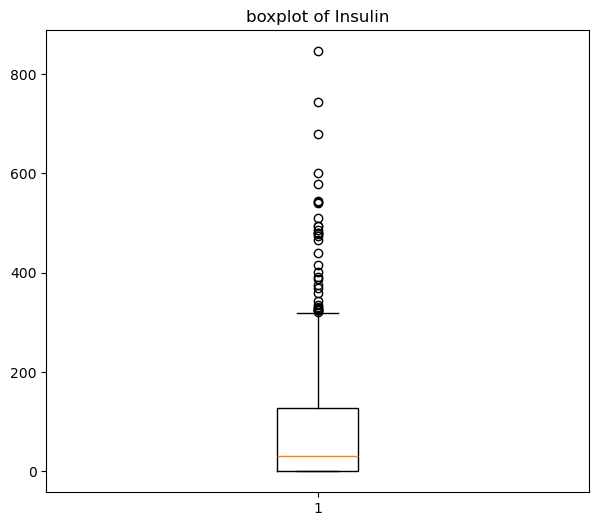

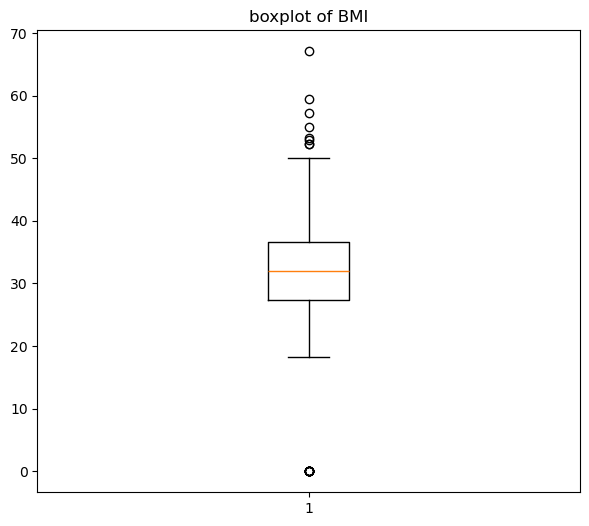

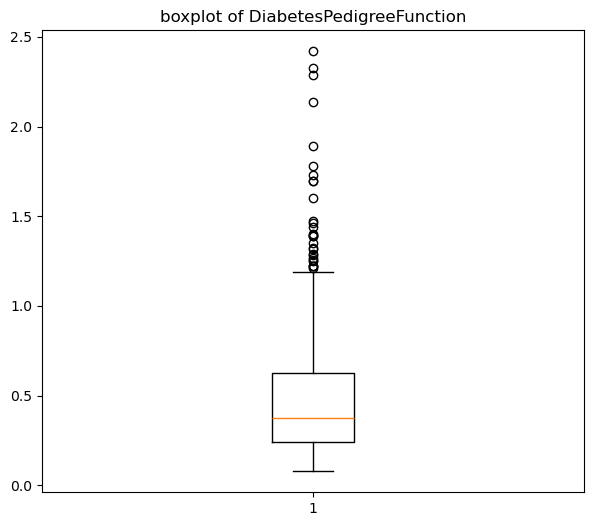

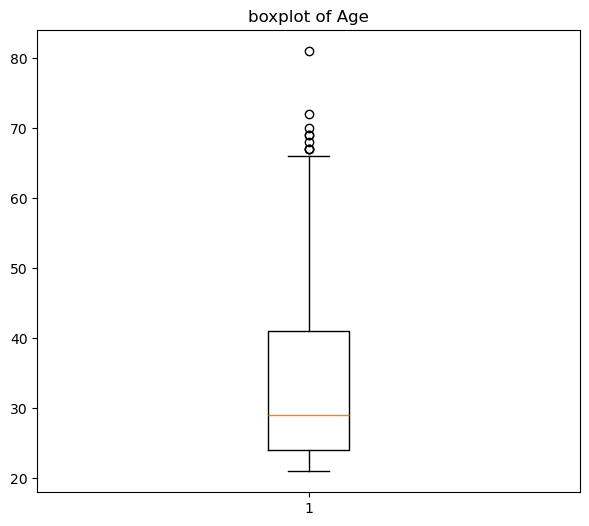

In [12]:
columns = ['Pregnancies',
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI',
    'DiabetesPedigreeFunction',
    'Age']
for i in columns:
    plt.figure(figsize=(7,6))
    plt.title(f"boxplot of {i}")
    plt.boxplot(df[i])
    plt.show()

*There are outliers present*

##### SCATTER PLOT

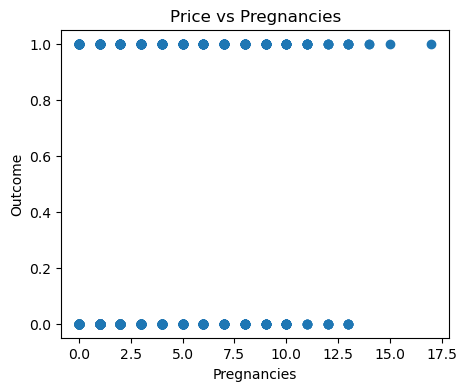

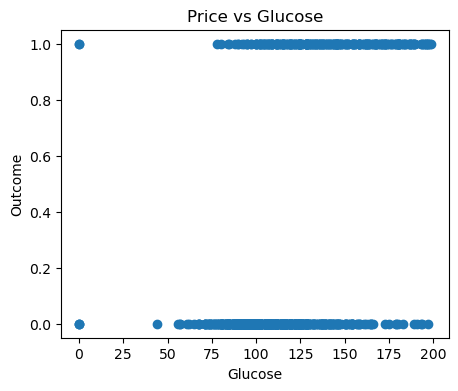

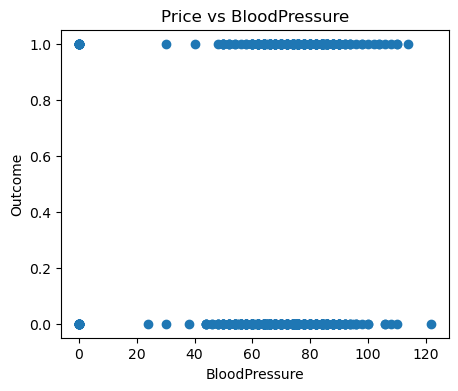

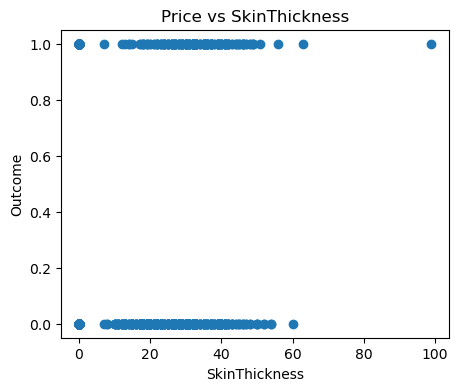

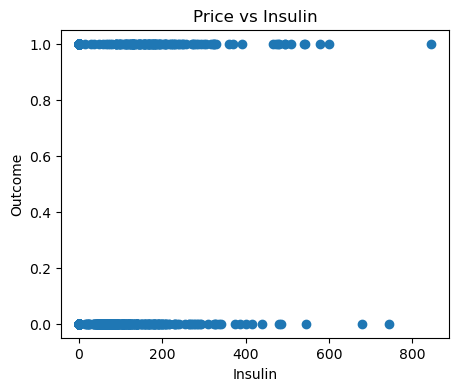

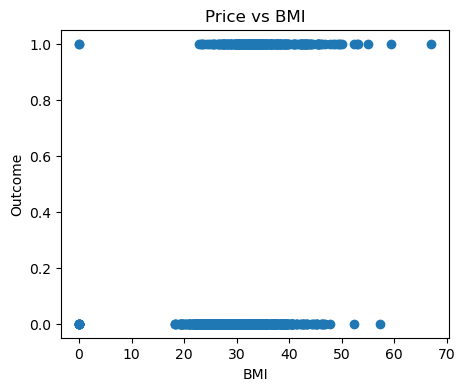

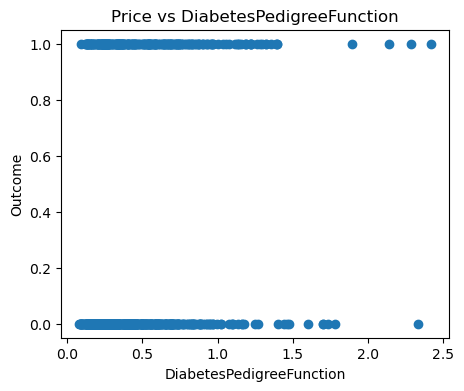

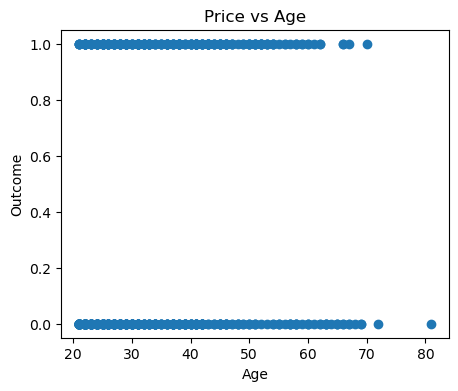

In [13]:
#SCATTER PLOT
columns = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin','BMI','DiabetesPedigreeFunction','Age']
for i in columns:
    plt.figure(figsize=(5,4))
    plt.scatter(df[i], df['Outcome'])
    plt.title(f'Price vs {i}')
    plt.xlabel(i)
    plt.ylabel('Outcome')
    plt.show()

Since the target variable (Outcome) is binary with values 0 and 1, the scatter plot displays two horizontal bands. This visualization confirms the class labels but does not clearly show the relationship between the feature and the target. Box plots or violin plots are more suitable for comparing feature distributions across the two outcome classes.

##### DATA CLEANING

In [21]:
# Remove the outliers
columns = ['Pregnancies',
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI',
    'DiabetesPedigreeFunction',
    'Age']
for i in columns:
    Q1 = df[i].quantile(0.25)
    Q3 = df[i].quantile(0.75)
    IQR = Q3 - Q1
    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR
    df[i] = df[i].clip(lower=lower_limit, upper=upper_limit)

#### EDA AFTER DATA CLEANING

##### HISTOGRAM

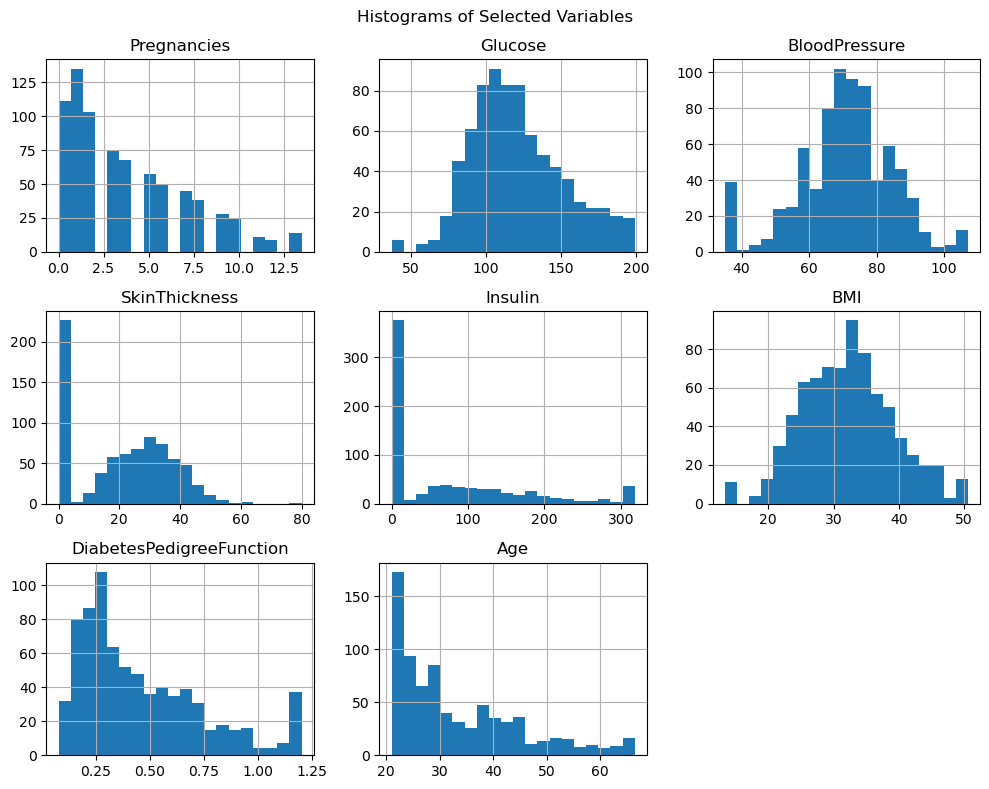

In [22]:
columns = ['Pregnancies',
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI',
    'DiabetesPedigreeFunction',
    'Age']
df[columns].hist(figsize=(10, 8), bins=20)

plt.suptitle("Histograms of Selected Variables")
plt.tight_layout()
plt.show()

##### BAR GRAPH

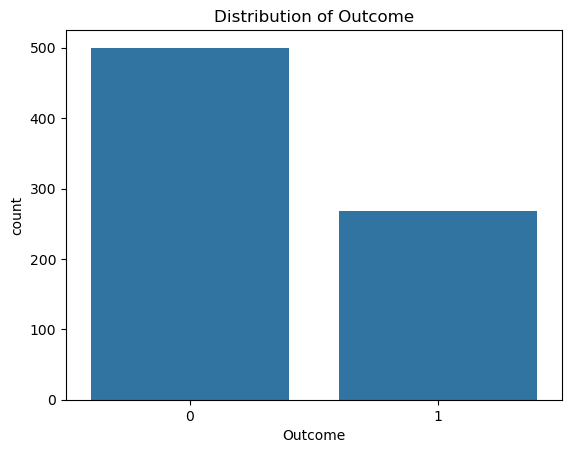

In [23]:
sns.countplot(x='Outcome', data=df)
plt.title("Distribution of Outcome")
plt.show()

##### BOXPLOT

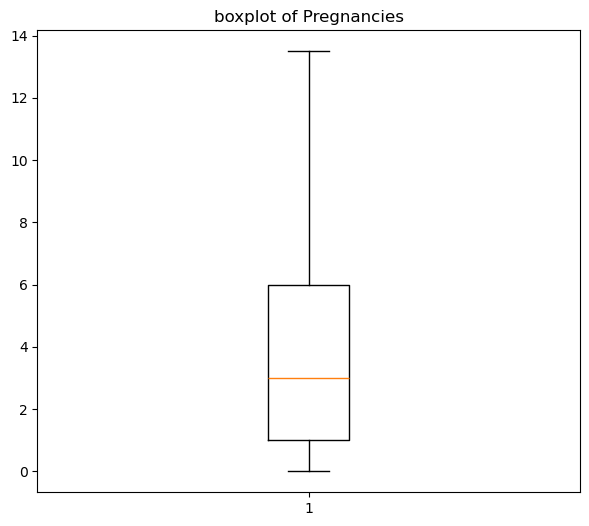

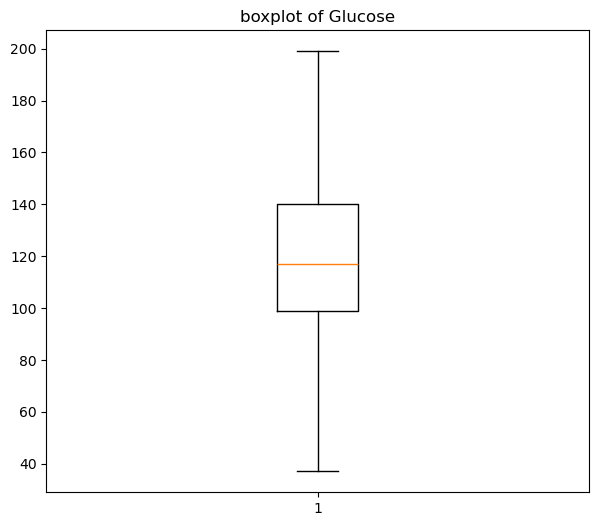

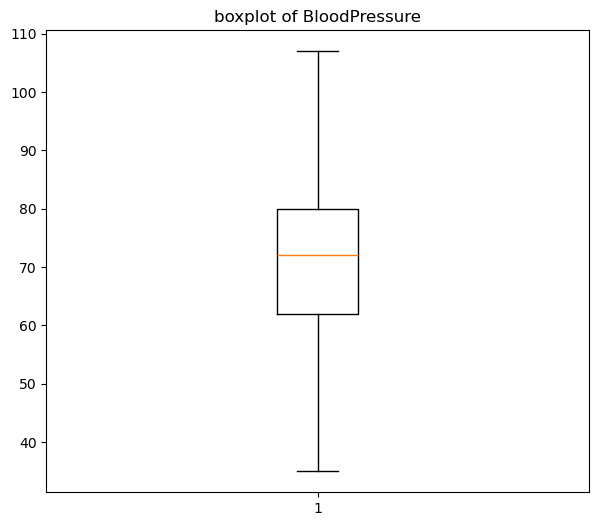

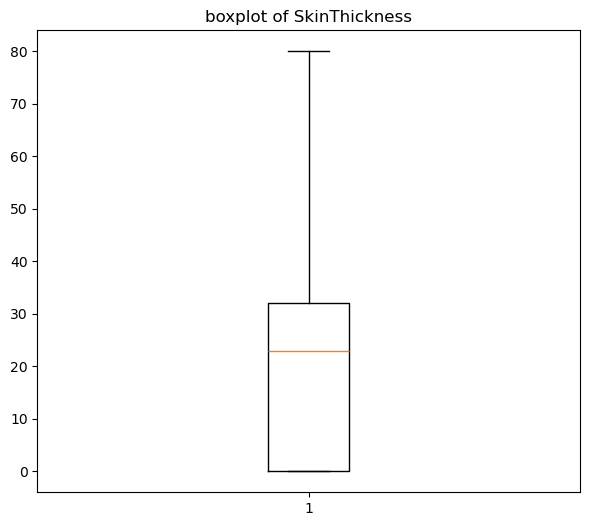

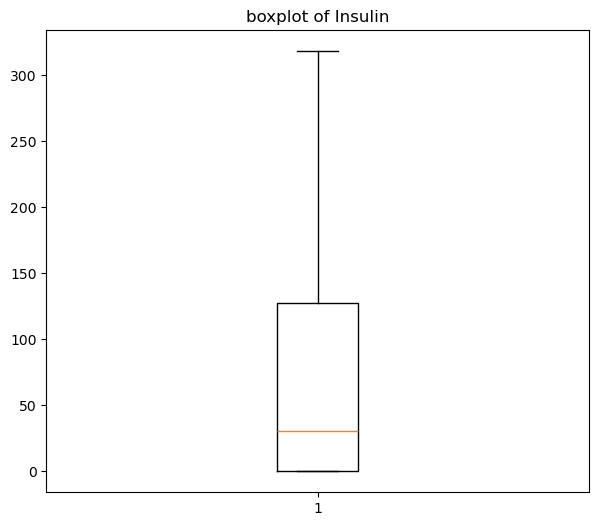

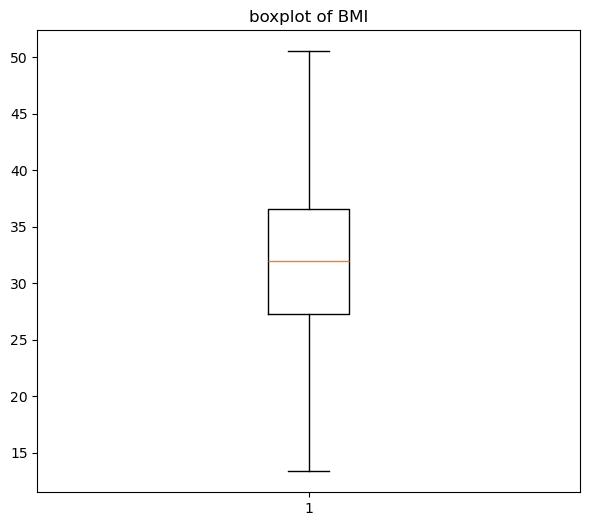

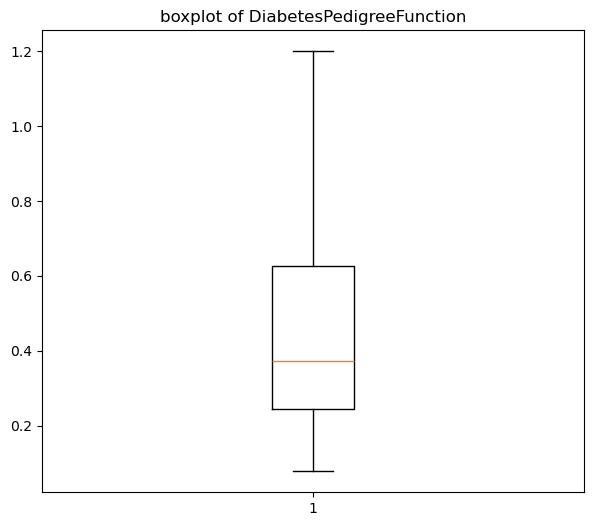

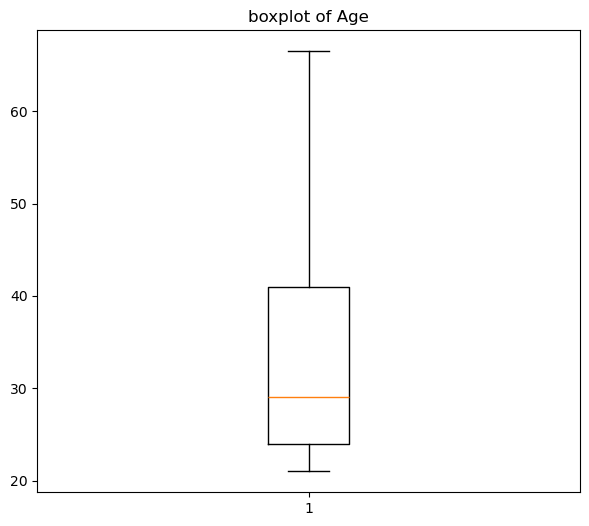

In [24]:
columns = ['Pregnancies',
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI',
    'DiabetesPedigreeFunction',
    'Age']
for i in columns:
    plt.figure(figsize=(7,6))
    plt.title(f"boxplot of {i}")
    plt.boxplot(df[i])
    plt.show()

##### SCATTER PLOT

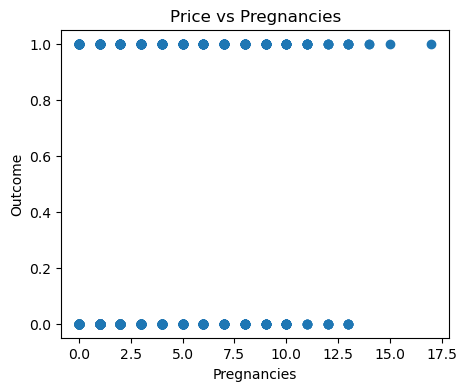

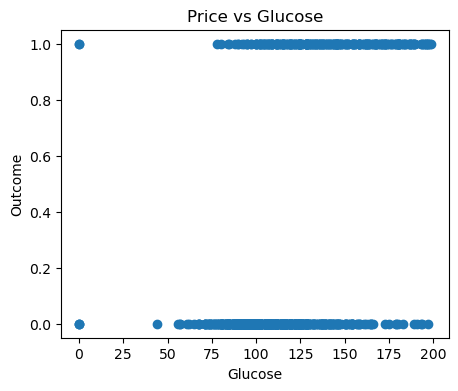

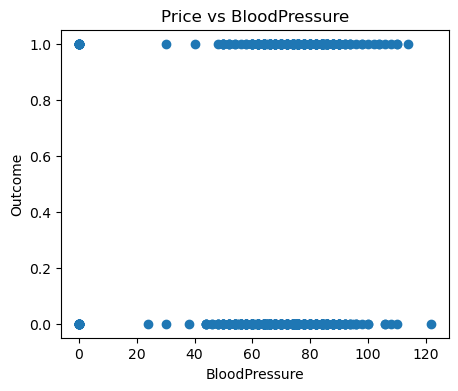

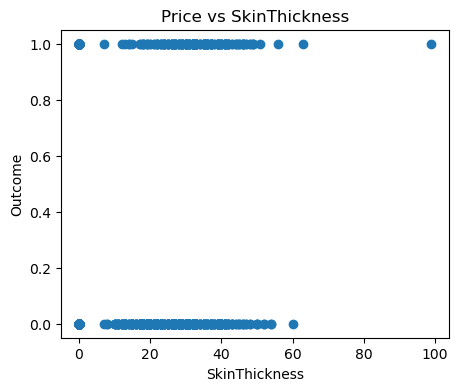

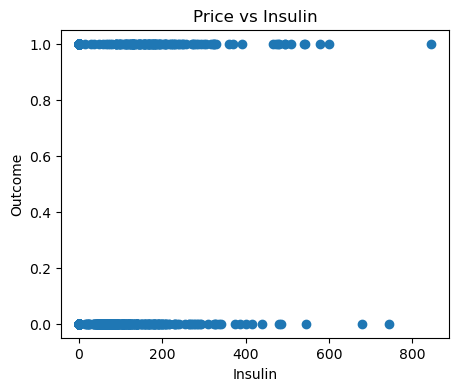

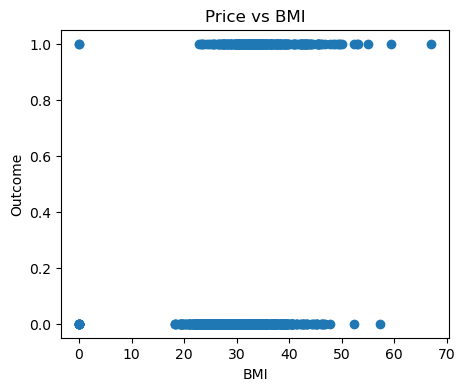

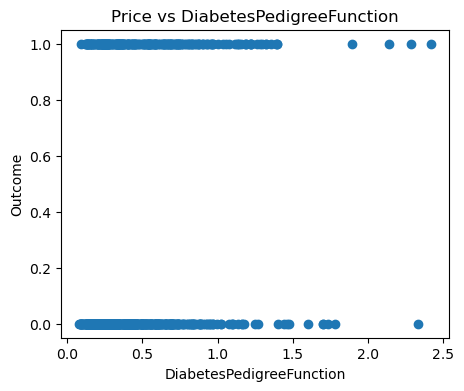

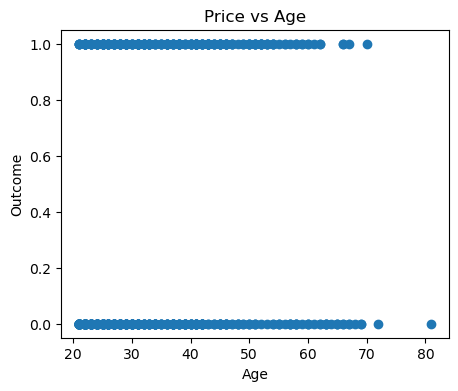

In [14]:
#SCATTER PLOT
columns = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin','BMI','DiabetesPedigreeFunction','Age']
for i in columns:
    plt.figure(figsize=(5,4))
    plt.scatter(df[i], df['Outcome'])
    plt.title(f'Price vs {i}')
    plt.xlabel(i)
    plt.ylabel('Outcome')
    plt.show()

### *There are no categorical features that require encoding because the target variable, Outcome, is already label encoded with values 0 and 1.*

2. Data Preprocessing

a. Handle missing values (e.g., imputation) :- 
There are no missing values.

b. Encode categorical variables :- There are no categorical values present.

3. Model Building

a. Build a logistic regression model using appropriate libraries (e.g., scikit-learn)

##### Correlation

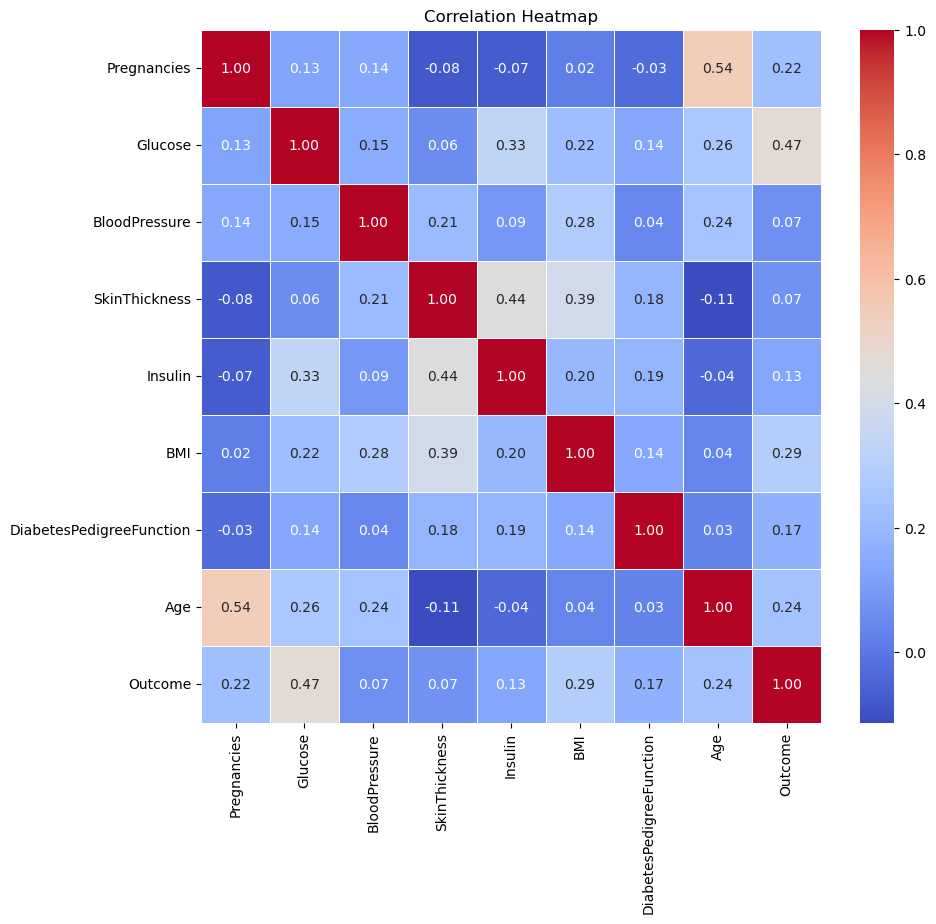

In [16]:
#heatmap
plt.figure(figsize=(10,9))
sns.heatmap(
    df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidth=0.5
)
plt.title("Correlation Heatmap")
plt.show()

*There are no high correlation values*

##### 3. Model Building

a. Build a logistic regression model using appropriate libraries (e.g., scikit-learn)

b. Train the model using the training data

##### Feature Selection

In [40]:
# Input features
x = df.drop('Outcome', axis=1)

# Target variable
y = df['Outcome']

##### Data Transformation

In [41]:
from sklearn.preprocessing import StandardScaler
SS = StandardScaler()
SS_x = SS.fit_transform(x)
SS_x = pd.DataFrame(SS_x, columns=x.columns)
SS_x.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,0.647150,0.861926,0.092691,0.914986,-0.787602,0.209359,0.588927,1.445691
1,-0.848970,-1.159433,-0.330201,0.536065,-0.787602,-0.784254,-0.378101,-0.189304
2,1.245598,1.984903,-0.471166,-1.295388,-0.787602,-1.252672,0.746595,-0.103252
3,-0.848970,-1.031093,-0.330201,0.157144,0.217583,-0.571337,-1.022787,-1.049828
4,-1.148194,0.508990,-2.162737,0.914986,1.008900,1.557835,2.596563,-0.017199


##### Data Partition

In [42]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(SS_x,y,test_size=0.2,random_state=42)

##### Model Selection

In [44]:
model = LogisticRegression(random_state=42)

##### Fit the model

In [45]:
model.fit(x_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


##### Predict the model

In [47]:
y_pred_train=model.predict(x_train)
y_pred_test=model.predict(x_test)

In [48]:
print('y_pred_train : ',y_pred_train)
print('y_pred_test : ', y_pred_test)

y_pred_train :  [0 1 0 1 1 0 0 1 0 0 0 1 0 0 1 1 1 0 0 1 1 0 0 0 0 0 0 0 0 1 1 0 0 0 1 0 0
 0 1 0 0 0 0 0 0 1 0 0 0 0 1 0 0 0 1 1 0 0 0 0 1 0 1 0 0 1 1 0 0 0 0 1 0 0
 0 0 0 0 0 0 0 0 0 0 0 1 0 0 1 0 0 0 1 0 0 0 0 0 1 0 0 1 0 0 0 0 1 1 0 0 0
 0 0 0 0 0 0 0 1 1 0 0 0 1 0 0 0 1 1 1 0 0 1 1 0 1 0 0 1 0 0 0 0 1 0 0 0 1
 1 0 0 0 0 0 0 0 0 1 1 0 0 0 1 0 0 0 0 0 1 0 0 0 0 0 1 0 0 0 0 0 0 0 1 1 0
 0 1 0 0 1 1 1 0 0 0 0 0 0 1 1 0 0 1 0 0 0 1 1 1 0 0 0 0 0 0 0 0 0 1 1 1 0
 1 0 0 0 0 1 1 1 0 0 1 0 0 0 0 0 0 1 1 1 1 1 1 1 0 0 0 0 0 0 0 1 0 0 0 0 0
 0 0 1 1 0 1 0 0 0 0 0 0 0 1 0 0 0 0 0 1 1 1 0 0 0 1 0 0 0 1 0 0 0 0 1 0 1
 0 0 1 1 0 0 1 1 0 0 0 0 0 0 0 0 0 0 0 1 1 1 0 0 0 0 1 0 0 0 0 0 0 1 0 1 1
 0 0 1 0 1 0 1 0 0 0 0 0 0 1 0 0 1 1 0 1 1 1 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0
 1 0 0 0 0 0 0 1 0 0 0 1 0 0 1 0 1 0 0 1 0 1 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0
 0 0 1 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0 1 0 1 0 0 0 0 0
 1 0 0 0 1 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0 0 0 0 1 0 0 0 0 1 0 0 0 0
 0 0 0 0 

##### 4. Model Evaluation

a. Evaluate the performance of the model on the testing data using accuracy, precision, recall, F1-score, and ROC-AUC score.

In [51]:
train_accuracy_score=accuracy_score(y_train,y_pred_train)
test_accuracy_score=accuracy_score(y_test,y_pred_test)
train_recall=recall_score(y_train,y_pred_train)
test_recall=recall_score(y_test,y_pred_test)
train_precision=precision_score(y_train,y_pred_train)
test_precision=precision_score(y_test,y_pred_test)
train_f1=f1_score(y_train,y_pred_train)
test_f1=f1_score(y_test,y_pred_test)

print(f'Training Accuracy Score: ',np.round(train_accuracy_score,2))
print(f'Testing Accuracy Score: ',np.round(test_accuracy_score,2))
print(f'\nTrain precision: ',np.round(train_precision,2))
print(f'Test precision: ',np.round(test_precision,2))
print(f'\nTrain recall: ',np.round(train_recall,2))
print(f'Test recall: ',np.round(test_recall,2))
print(f'\nTrain f1: ',np.round(train_f1,2))
print(f'Test f1: ',np.round(test_f1,2))

Training Accuracy Score:  0.78
Testing Accuracy Score:  0.75

Train precision:  0.73
Test precision:  0.65

Train recall:  0.58
Test recall:  0.65

Train f1:  0.65
Test f1:  0.65


In [57]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Make predictions
y_pred = model.predict(x_test)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

# Display results
print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1-Score :", round(f1, 4))

Accuracy : 0.7532
Precision: 0.6545
Recall   : 0.6545
F1-Score : 0.6545


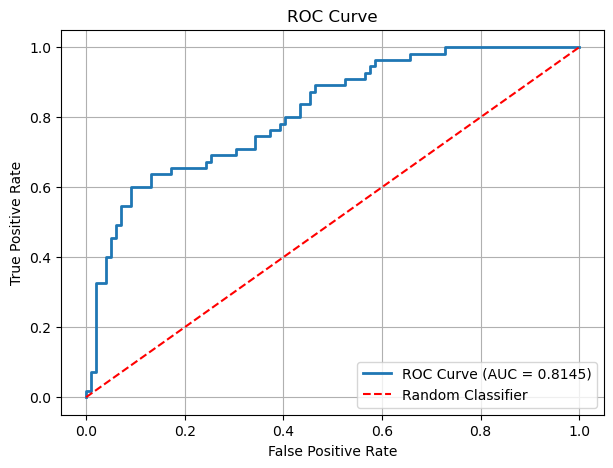

ROC-AUC Score: 0.8145


In [58]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Predict probabilities
y_prob = model.predict_proba(x_test)[:, 1]

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

# Calculate ROC-AUC score
roc_auc = roc_auc_score(y_test, y_prob)

# Plot ROC Curve
plt.figure(figsize=(7,5))
plt.plot(fpr, tpr, linewidth=2, label=f'ROC Curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], 'r--', label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

print("ROC-AUC Score:", round(roc_auc, 4))

5. Interpretation

a. Interpret the coefficients of the logistic regression model

b. Discuss the significance of features in predicting the target variable (survival probability in this case).

In [59]:
coefficients = pd.DataFrame({
    'Feature': x.columns,
    'Coefficient': model.coef_[0]
})

print(coefficients)

                    Feature  Coefficient
0               Pregnancies     0.200366
1                   Glucose     1.088289
2             BloodPressure    -0.249305
3             SkinThickness     0.036520
4                   Insulin    -0.218544
5                       BMI     0.777954
6  DiabetesPedigreeFunction     0.284662
7                       Age     0.449256


Interpretation of Coefficients: The Logistic Regression coefficients indicate how each feature influences the likelihood of diabetes. Glucose (1.088289) has the highest positive coefficient, making it the strongest predictor of diabetes. BMI (0.777954) is the second most influential feature, followed by Age (0.449256), DiabetesPedigreeFunction (0.284662), Pregnancies (0.200366), and SkinThickness (0.036520), all of which positively contribute to the probability of diabetes. In contrast, BloodPressure (-0.249305) and Insulin (-0.218544) have negative coefficients, indicating that higher values of these features are associated with a lower predicted probability of diabetes in this fitted model.

Feature Significance: Among all the predictors, Glucose is the most significant feature for predicting diabetes, followed by BMI and Age, as they have the largest positive coefficients. DiabetesPedigreeFunction, Pregnancies, and SkinThickness also contribute positively, although their influence is comparatively smaller. BloodPressure and Insulin have negative coefficients, suggesting an inverse relationship with the predicted outcome in this model. Overall, Glucose, BMI, and Age are the most influential features in predicting diabetes.

6. Deployment with Streamlit

saving the model

In [62]:
import pickle

with open("model.pkl", "wb") as file:
    pickle.dump(model, file)

In [63]:
with open("scaler.pkl", "wb") as file:
    pickle.dump(SS, file)

In [65]:
feature_names = x.columns.tolist()

with open("features.pkl", "wb") as file:
    pickle.dump(feature_names, file)

Interview Questions :-

1. What is the difference between precision and recall?

Precision measures how many of the predicted positive cases are actually positive. It focuses on minimizing False Positives.Recall measures how many of the actual positive cases are correctly identified. It focuses on minimizing False Negatives.

2. What is cross-validation, and why is it important in binary classification?

Cross-validation is a model evaluation technique used to measure how well a model generalizes to unseen data. In k-fold cross-validation, the dataset is divided into k equal parts (folds). The model is trained on k−1 folds and tested on the remaining fold. This process is repeated k times, with each fold used once as the test set, and the average performance is calculated.

* It is important in binary classification because :-

It provides a more reliable estimate of model performance.
It helps detect overfitting and underfitting.
It ensures the model generalizes well to new, unseen data.
It makes better use of the available dataset, especially when the dataset is small.